# Step 3 — Add better external data (Spotify charts × happiness)

## Why more data?
Our original music file only covers **10 countries** of synthetic users. AutoML found almost no link to happiness.

What we need is **country-level music taste** for many countries — then join happiness on `country`.

## Datasets we use
| Source | Role |
|--------|------|
| [Top Spotify Songs in 73 Countries](https://www.kaggle.com/datasets/asaniczka/top-spotify-songs-in-73-countries-daily-updated) | Charts + audio features (`valence`, `energy`, …) per country |
| Our cleaned happiness | National well-being / GDP factors |
| Optional: [WHR 2020–2024 on Kaggle](https://www.kaggle.com/datasets/mayankkacha/world-happiness-report-2020-to-2024) | Extra happiness years |

This notebook runs on a **small public sample** already in `data/external/`.  
For the full ~170 MB Kaggle file: put your API token in `~/.kaggle/kaggle.json`, then run `./scripts/download_kaggle_datasets.sh`.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pycountry

sns.set_theme(style="whitegrid")
DATA = Path(".")
RAW = DATA / "data" / "raw" / "spotify_73_countries"
SAMPLE = DATA / "data" / "external" / "universal_top_spotify_songs_sample.csv"

# Prefer full Kaggle download if present
candidates = list(RAW.glob("*.csv")) if RAW.exists() else []
spotify_path = candidates[0] if candidates else SAMPLE
print("Using:", spotify_path.resolve())

spotify = pd.read_csv(spotify_path)
print("Shape:", spotify.shape)
print("Columns:", list(spotify.columns))
spotify.head(3)


Using: /home/wissemsirat/Documents/Projects/musicml/data/external/universal_top_spotify_songs_sample.csv
Shape: (5000, 25)
Columns: ['spotify_id', 'name', 'artists', 'daily_rank', 'daily_movement', 'weekly_movement', 'country', 'snapshot_date', 'popularity', 'is_explicit', 'duration_ms', 'album_name', 'album_release_date', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature']


,spotify_id,name,artists,daily_rank,daily_movement,weekly_movement,country,snapshot_date,popularity,is_explicit,...,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature
0,2RkZ5LkEzeHGRsmDqKwmaJ,Ordinary,Alex Warren,1,1,0,NaN,2025-06-11,95,False,...,2,-6.141,1,0.0600,0.704000,0.000007,0.0550,0.391,168.115,3
1,42UBPzRMh5yyz0EDPr6fr1,Manchild,Sabrina Carpenter,2,-1,48,NaN,2025-06-11,89,True,...,7,-5.087,1,0.0572,0.122000,0.000000,0.3170,0.811,123.010,4
2,0FTmksd2dxiE5e3rWyJXs6,back to friends,sombr,3,0,1,NaN,2025-06-11,98,False,...,1,-2.291,1,0.0301,0.000094,0.000088,0.0929,0.235,92.855,4


## Map ISO country codes → happiness country names

Spotify uses codes like `US`, `FR`. Happiness uses `United States`, `France`.


In [2]:
ALIASES = {
    "United States of America": "United States",
    "Korea, Republic of": "South Korea",
    "Czechia": "Czechia",  # happiness has both Czechia and Czech Republic in some years
    "Russian Federation": "Russia",
    "Bolivia, Plurinational State of": "Bolivia",
    "Taiwan, Province of China": "Taiwan Province of China",
    "Venezuela, Bolivarian Republic of": "Venezuela",
    "Moldova, Republic of": "Moldova",
    "Iran, Islamic Republic of": "Iran",
    "Syrian Arab Republic": "Syria",
    "Viet Nam": "Vietnam",
    "Türkiye": "Turkiye",
    "Turkey": "Turkiye",
}

def iso_to_name(code: str) -> str | None:
    if pd.isna(code) or code in ("", "Global"):
        return None
    c = pycountry.countries.get(alpha_2=str(code))
    if c is None:
        return None
    name = c.name
    return ALIASES.get(name, name)

s = spotify.copy()
s["country"] = s["country"].replace({np.nan: None})
s["country_name"] = s["country"].map(iso_to_name)
print("Rows with country name:", s["country_name"].notna().sum())
print("Unique countries:", s["country_name"].nunique())


Rows with country name: 4900
Unique countries: 71


## Aggregate audio features per country

`valence` ≈ how musically “positive / happy” tracks sound (Spotify’s definition — not the same as national happiness, but a natural feature to correlate).


In [3]:
audio_cols = [
    "valence", "energy", "danceability", "acousticness",
    "speechiness", "instrumentalness", "liveness",
    "tempo", "loudness", "popularity",
]
audio_cols = [c for c in audio_cols if c in s.columns]

country_music = (
    s.dropna(subset=["country_name"])
     .groupby("country_name", as_index=False)[audio_cols]
     .mean()
)
print(country_music.shape)
country_music.sort_values("valence", ascending=False).head()


(71, 11)


,country_name,valence,energy,danceability,acousticness,speechiness,instrumentalness,liveness,tempo,loudness,popularity
53,Romania,0.711396,0.738780,0.75929,0.205869,0.097915,0.020376,0.181366,132.50517,-5.98750,61.71
7,Bulgaria,0.651496,0.774280,0.70428,0.147082,0.128804,0.018955,0.172254,138.71214,-5.51392,57.76
39,Mexico,0.651120,0.696726,0.73968,0.359259,0.085914,0.037759,0.146982,116.89666,-7.73428,85.22
18,Estonia,0.647640,0.776180,0.67754,0.109317,0.091772,0.019880,0.189124,129.42904,-6.02204,65.02
23,Guatemala,0.631640,0.674566,0.72770,0.348570,0.074734,0.037763,0.135854,115.24188,-7.70710,86.96


In [4]:
happ = pd.read_csv(DATA / "cleaned" / "happiness_clean.csv")
latest_year = int(happ["year"].max())
happ_latest = happ.loc[happ["year"] == latest_year].copy()
print(f"Happiness year {latest_year}, countries={len(happ_latest)}")

# Also try alternate names present in happiness
name_fallbacks = {
    "Czechia": "Czech Republic",
    "Czech Republic": "Czechia",
    "Taiwan": "Taiwan Province of China",
    "Taiwan Province of China": "Taiwan",
    "Turkey": "Turkiye",
    "Turkiye": "Turkey",
}

def match_country(name):
    names = set(happ_latest["country"])
    if name in names:
        return name
    alt = name_fallbacks.get(name)
    if alt in names:
        return alt
    return None

country_music["happ_key"] = country_music["country_name"].map(match_country)
print("Unmatched:", country_music.loc[country_music["happ_key"].isna(), "country_name"].tolist())

merged = country_music.dropna(subset=["happ_key"]).merge(
    happ_latest, left_on="happ_key", right_on="country", how="inner"
)
print("Merged countries:", len(merged))

out = DATA / "cleaned"
out.mkdir(exist_ok=True)
merged.to_csv(out / "country_spotify_x_happiness.csv", index=False)
merged.head()


Happiness year 2024, countries=140
Unmatched: ['Belarus']
Merged countries: 70


,country_name,valence,energy,danceability,acousticness,speechiness,instrumentalness,liveness,tempo,loudness,...,country,regional_indicator,happiness_score,gdp_per_capita,social_support,healthy_life_expectancy,freedom_to_make_life_choices,generosity,perceptions_of_corruption,year
0,Argentina,0.526754,0.637746,0.63748,0.275635,0.080770,0.062873,0.195780,120.62448,-8.65890,...,Argentina,Latin America and Caribbean,6.1881,7.29612,0.85449,73.0,0.78851,0.21822,0.13990,2024
1,Australia,0.500000,0.644200,0.60532,0.229715,0.060392,0.001856,0.170786,121.46508,-6.45030,...,Australia,North America and ANZ,7.0569,8.66266,0.90385,76.0,0.87599,0.56188,0.56224,2024
2,Austria,0.557280,0.739640,0.69164,0.165518,0.095796,0.018998,0.183946,127.28598,-6.05762,...,Austria,Western Europe,6.9047,8.80752,0.82671,76.0,0.81399,0.53362,0.52956,2024
3,Belgium,0.549996,0.656860,0.69190,0.237190,0.109720,0.015816,0.147368,126.93616,-6.80594,...,Belgium,Western Europe,6.8942,8.72705,0.89106,76.0,0.84413,0.42531,0.54042,2024
4,Bolivia,0.555754,0.645366,0.68124,0.313240,0.115990,0.067186,0.160210,116.81728,-8.97734,...,Bolivia,Latin America and Caribbean,5.7843,5.68578,0.72960,70.0,0.83335,0.24842,0.10575,2024


## Correlations — musical taste vs national happiness

Strongest |corr|:
acousticness      social_support               0.565
loudness          gdp_per_capita               0.497
acousticness      gdp_per_capita               0.463
                  healthy_life_expectancy      0.439
speechiness       generosity                   0.425
tempo             gdp_per_capita               0.425
instrumentalness  gdp_per_capita               0.418
acousticness      happiness_score              0.409
danceability      generosity                   0.408
instrumentalness  perceptions_of_corruption    0.347
loudness          perceptions_of_corruption    0.336
                  healthy_life_expectancy      0.332
dtype: float64


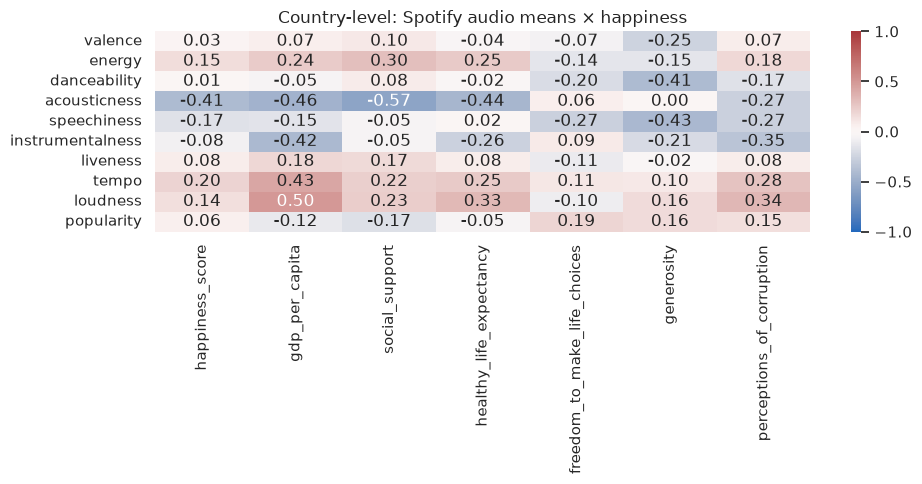

In [5]:
happ_cols = [
    "happiness_score", "gdp_per_capita", "social_support",
    "healthy_life_expectancy", "freedom_to_make_life_choices",
    "generosity", "perceptions_of_corruption",
]
cross = merged[audio_cols + happ_cols].corr(method="pearson").loc[audio_cols, happ_cols]
print("Strongest |corr|:")
print(cross.stack().abs().sort_values(ascending=False).head(12).round(3))

plt.figure(figsize=(10, 5))
sns.heatmap(cross, annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1)
plt.title("Country-level: Spotify audio means × happiness")
plt.tight_layout()
plt.show()
cross.to_csv(out / "corr_spotify_audio_x_happiness.csv")


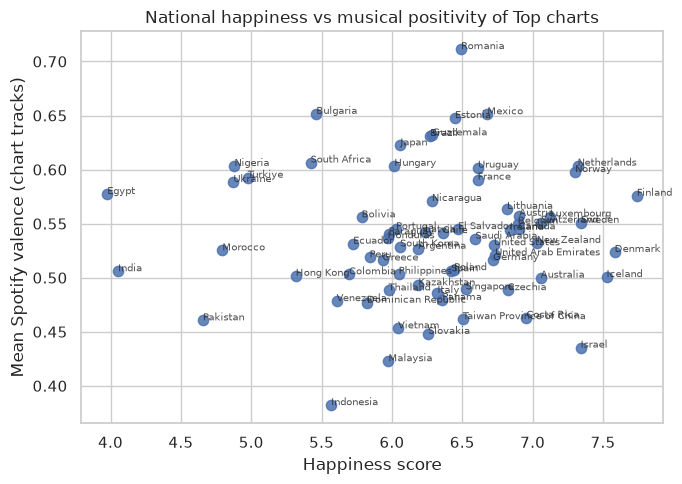

In [6]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(merged["happiness_score"], merged["valence"], s=55, alpha=0.85)
for _, r in merged.iterrows():
    ax.annotate(r["happ_key"], (r["happiness_score"], r["valence"]), fontsize=7, alpha=0.8)
ax.set_xlabel("Happiness score")
ax.set_ylabel("Mean Spotify valence (chart tracks)")
ax.set_title("National happiness vs musical positivity of Top charts")
plt.tight_layout()
plt.show()


## How to load the FULL Kaggle dataset

1. Create a free account on [kaggle.com](https://www.kaggle.com)
2. Settings → API → **Create New Token** → download `kaggle.json`
3. ```bash
   mkdir -p ~/.kaggle
   mv ~/Downloads/kaggle.json ~/.kaggle/kaggle.json
   chmod 600 ~/.kaggle/kaggle.json
   ./scripts/download_kaggle_datasets.sh
   ```
4. Re-run this notebook — it auto-detects `data/raw/spotify_73_countries/*.csv`

With the full daily history you can average over months/years (more stable than a 1–2 day sample).
